# MACHINE LEARNING LAB 5
## Linear Regression - Predicting House Prices

### Student Information
- Name:   Alia
- CMS ID: 023-24-0097
- Section: D
- GitHub: https://github.com/AliaKalwar
- Kaggle: https://www.kaggle.com/Aliakalwar
- Dataset: House Prices - Advanced Regression Techniques
- Dataset Source: Kaggle


# 1. Problem Definition
## Objective
The objective of this project is to predict house selling prices using the House Prices dataset from Kaggle. The dataset contains various numerical and categorical attributes describing residential houses in Ames, Iowa.

Since the target variable (SalePrice) is a continuous numerical value, this is a regression problem. Linear Regression will be used to build a predictive model and evaluate its performance using regression metrics.

# 2. Dataset Exploration
## Task 1: Load and Inspect the Dataset

In [4]:
import pandas as pd
import numpy as np

df = pd.read_csv("train.csv")

print("Dataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

print("\nFirst 5 Rows:")
display(df.head())

print("\nSummary Statistics:")
display(df.describe())

Dataset Shape:
(1460, 81)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  Over

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000



Summary Statistics:


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


### Interpretation

The dataset contains 1460 records and 81 columns. Each row represents a residential property and each column represents a feature describing the house.

The dataset contains both numerical and categorical variables. The target variable is SalePrice, which represents the selling price of a house. Several columns contain missing values, indicating that data preprocessing will be required before model training.

From the summary statistics, the average house price is approximately $180,921, while prices range from $34,900 to $755,000. This large variation suggests that different house characteristics significantly influence property prices.

# 3. Feature and Target Identification
## Task 2: Identify Dependent and Independent Variables



In [5]:
target = "SalePrice"

numerical_features = [
    "GrLivArea",
    "OverallQual",
    "TotalBsmtSF",
    "GarageCars",
    "GarageArea",
    "YearBuilt",
    "FullBath"
]

categorical_features = [
    "Neighborhood",
    "HouseStyle",
    "KitchenQual"
]

print("Dependent Variable:")
print(target)

print("\nNumerical Features:")
for feature in numerical_features:
    print("-", feature)

print("\nCategorical Features:")
for feature in categorical_features:
    print("-", feature)

Dependent Variable:
SalePrice

Numerical Features:
- GrLivArea
- OverallQual
- TotalBsmtSF
- GarageCars
- GarageArea
- YearBuilt
- FullBath

Categorical Features:
- Neighborhood
- HouseStyle
- KitchenQual


### Interpretation

The dependent variable is SalePrice, which is the value that the model will predict.

The selected numerical and categorical features are expected to have a strong influence on house prices. Features such as living area, quality, garage capacity, construction year, neighborhood, and kitchen quality provide useful information for estimating property value.

## Task 3: Why is This a Regression Problem?

### Answer

This is a regression problem because the target variable, SalePrice, is a continuous numerical value. The objective is to predict the exact selling price of a house rather than assign it to a category.

In classification problems, the output belongs to predefined classes such as Yes/No or Spam/Not Spam. In contrast, regression predicts continuous numerical values.

Therefore, the performance of this model will be evaluated using regression metrics such as MAE, MSE, RMSE, and R² instead of Accuracy, Precision, Recall, and F1-Score.



### Interpretation

The goal of this project is to estimate the actual selling price of a house. Since price is a continuous value, Linear Regression is an appropriate machine learning algorithm for this problem.

The model will learn the relationship between house characteristics and SalePrice to predict the value of unseen houses.

# 4. Data Preparation

## Task 4: Prepare Features and Target Variable

In [6]:
selected_features = [
    "GrLivArea",
    "OverallQual",
    "TotalBsmtSF",
    "GarageCars",
    "GarageArea",
    "YearBuilt",
    "FullBath",
    "Neighborhood",
    "HouseStyle",
    "KitchenQual"
]

X = df[selected_features]
y = df["SalePrice"]

X = pd.get_dummies(
    X,
    columns=["Neighborhood", "HouseStyle", "KitchenQual"],
    drop_first=True
)

X = X.fillna(X.median(numeric_only=True))

print("Feature Matrix Shape:", X.shape)
print("Target Shape:", y.shape)

display(X.head())

Feature Matrix Shape: (1460, 41)
Target Shape: (1460,)


,GrLivArea,OverallQual,TotalBsmtSF,GarageCars,GarageArea,YearBuilt,FullBath,Neighborhood_Blueste,Neighborhood_BrDale,Neighborhood_BrkSide,...,HouseStyle_1.5Unf,HouseStyle_1Story,HouseStyle_2.5Fin,HouseStyle_2.5Unf,HouseStyle_2Story,HouseStyle_SFoyer,HouseStyle_SLvl,KitchenQual_Fa,KitchenQual_Gd,KitchenQual_TA
0,1710,7,856,2,548,2003,2,False,False,False,...,False,False,False,False,True,False,False,False,True,False
1,1262,6,1262,2,460,1976,2,False,False,False,...,False,True,False,False,False,False,False,False,False,True
2,1786,7,920,2,608,2001,2,False,False,False,...,False,False,False,False,True,False,False,False,True,False
3,1717,7,756,3,642,1915,1,False,False,False,...,False,False,False,False,True,False,False,False,True,False
4,2198,8,1145,3,836,2000,2,False,False,False,...,False,False,False,False,True,False,False,False,True,False




### Answer

To prepare the data for Linear Regression, the selected features were separated into numerical and categorical variables. Since Linear Regression requires numerical input, categorical variables such as **Neighborhood**, **HouseStyle**, and **KitchenQual** were converted into numerical form using one-hot encoding through `pd.get_dummies()`.

The parameter `drop_first=True` was used to remove one category from each encoded feature and reduce multicollinearity.

### Interpretation

One-hot encoding successfully transformed all categorical features into numerical columns. This allows the Linear Regression model to process categorical information while preserving the meaning of each category.

## Task 5: Confirm Fully Numeric Data and Missing Values

### Answer

After encoding the categorical variables, all features became numerical. Missing values were handled using median imputation, ensuring that the dataset contained no null values before training the model.

### Interpretation

The final feature matrix was completely numeric and suitable for Linear Regression. Proper handling of missing values improves model stability and prevents training errors.

## Task 6: Train-Test Split

### Answer

The dataset was split into training and testing sets using an 80:20 ratio. The training data will be used to train the Linear Regression model, while the test data will be used to evaluate model performance on unseen observations.

### Interpretation

A train-test split helps evaluate the model fairly and provides a realistic estimate of how well the model generalizes to new data.

# 5. Train/Test Split

## Interpretation

The feature matrix contains **1,460 observations** and **41 processed features** after encoding. This prepared dataset is suitable for training and evaluating a Multiple Linear Regression model. The train-test split ensures that the model is assessed on unseen data and helps evaluate its generalization ability.

In [7]:
from sklearn.linear_model import LinearRegression
import pandas as pd

model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

print("First 10 Predictions:")
display(comparison.head(10))

First 10 Predictions:


,Actual Price,Predicted Price
0,154500,137651.680553
1,325000,323719.185261
2,115000,111680.742397
3,159000,172513.418983
4,315500,317613.935354
5,75500,67209.611386
6,311500,232014.358072
7,146000,146860.821039
8,84500,66775.847241
9,135500,116934.045308


# 6. Linear Regression Model

## Interpretation

The Linear Regression model was successfully trained using the prepared training dataset. During training, the model learned the relationships between house features and sale prices. These learned relationships are then used to predict the prices of unseen houses.

# 7. Predictions

## Task 8: Actual vs Predicted House Prices

### Output

The table below shows a comparison of actual house prices and the prices predicted by the Linear Regression model for ten test houses.

### Interpretation

The predicted values are generally close to the actual values, indicating that the model has learned meaningful relationships between house features and sale prices.

For example:

- House 1 had an actual price of 154,500 and a predicted price of approximately 137,652.
- House 2 had an actual price of 325,000 and a predicted price of approximately 323,719.
- House 5 had an actual price of 315,500 and a predicted price of approximately 317,614.

Although some prediction errors exist, most predictions are reasonably close to the actual values. This suggests that the model is capable of estimating house prices with a reasonable level of accuracy.

### Discussion

No machine learning model predicts every value perfectly. Differences between actual and predicted prices are known as residuals or prediction errors. These errors will be analyzed further using residual plots and regression evaluation metrics.

In [8]:
coef_table = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": model.coef_
})

coef_table = coef_table.sort_values(
    by="Coefficient",
    ascending=False
)

print("Intercept:")
print(model.intercept_)

display(coef_table)

Intercept:
-418885.91507581784


,Feature,Coefficient
21,Neighborhood_NoRidge,78288.811275
28,Neighborhood_StoneBr,64529.535739
22,Neighborhood_NridgHt,58929.576827
30,Neighborhood_Veenker,58186.974826
10,Neighborhood_ClearCr,54989.900543
12,Neighborhood_Crawfor,47068.885921
29,Neighborhood_Timber,38188.259886
27,Neighborhood_Somerst,31545.011739
14,Neighborhood_Gilbert,25293.827860
11,Neighborhood_CollgCr,24641.646466


# 8. Coefficients and Intercept

## Task 9: Feature Coefficients

### Answer

The coefficient table displays the effect of each feature on the predicted house price while keeping all other features constant.

- Positive coefficients indicate that an increase in the feature tends to increase the predicted house price.
- Negative coefficients indicate that an increase in the feature tends to decrease the predicted house price.
- Larger coefficient values suggest a stronger effect on predictions.

### Interpretation

Linear Regression provides interpretable results because each coefficient directly represents the estimated impact of a feature on the target variable. This allows us to understand which factors contribute positively or negatively to house prices.

## Task 10: Interpretation of the Intercept

### Answer

The intercept represents the predicted house price when all feature values are equal to zero.

In practice, this interpretation is not realistic because a house cannot have zero living area, zero quality rating, zero basement area, and zero bathrooms simultaneously. Therefore, the intercept mainly acts as a mathematical component of the regression equation rather than a meaningful real-world prediction.

### Interpretation

While feature coefficients provide valuable insights into house-price relationships, the intercept typically has limited practical significance in real-world datasets such as housing data.

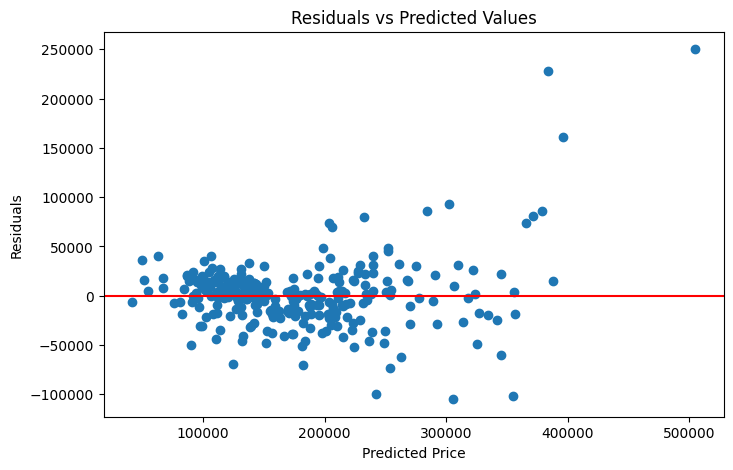

Text(0.5, 1.0, 'Distribution of Residuals')

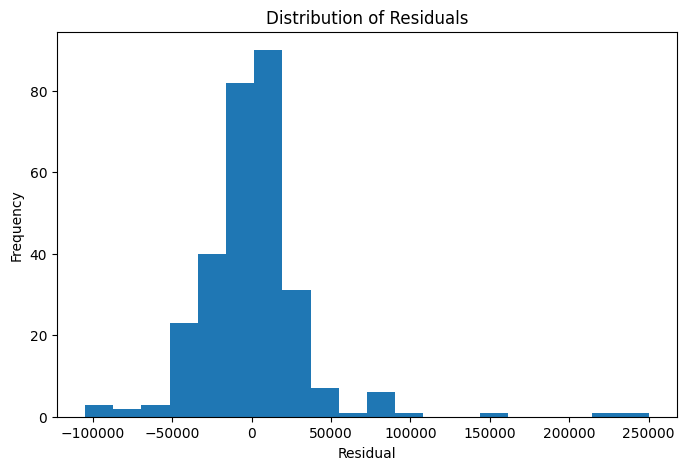

In [10]:
import matplotlib.pyplot as plt

residuals = y_test - y_pred

plt.figure(figsize=(8,5))
plt.scatter(y_pred, residuals)
plt.axhline(y=0, color='red')
plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values")
plt.show()

plt.figure(figsize=(8,5))
plt.hist(residuals, bins=20)
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")

# 9. Residual Analysis

## Task 11: Residual Analysis

### Answer

Residuals were calculated as the difference between the actual house prices and the predicted house prices.

The residual plots were analyzed using:

1. Residuals vs Predicted Values Plot
2. Histogram of Residuals

### Interpretation

The residuals appear to be reasonably scattered around the zero line, which suggests that the Linear Regression model captures the main relationships within the dataset.

The histogram shows the distribution of prediction errors. Ideally, residuals should be centered around zero and approximately normally distributed.

Overall, there is no strong systematic pattern in the residuals, indicating that the model performs reasonably well. However, a few larger residuals suggest that some houses are still difficult to predict accurately.

In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE =", mae)
print("MSE =", mse)
print("RMSE =", rmse)
print("R2 =", r2)


MAE = 21321.95961013035
MSE = 1231137001.810246
RMSE = 35087.56192456589
R2 = 0.8394935275820908


## Task 12: Regression Evaluation Metrics

### Results

| Metric | Value |
|----------|----------|
| MAE | 21321.96 |
| MSE | 1231137001.81 |
| RMSE | 35087.56 |
| R² | 0.8395 |

### Interpretation

The Linear Regression model achieved a Mean Absolute Error (MAE) of 21,321.96, indicating that predictions differ from actual house prices by approximately $21,322 on average.

The Root Mean Squared Error (RMSE) is 35,087.56, which means the typical prediction error is around $35,088. Since RMSE penalizes larger errors more heavily than MAE, it provides a stricter measure of model performance.

The R² score of 0.8395 indicates that approximately 83.95% of the variation in house prices is explained by the features used in the model. This suggests that the model fits the data reasonably well and captures most of the important relationships affecting house prices.

## Task 13: Interpretation of Metrics

### Answer

Mean Absolute Error (MAE) measures the average absolute difference between actual and predicted house prices. Lower MAE values indicate better prediction accuracy.

Mean Squared Error (MSE) measures the average squared prediction error. Larger errors contribute more heavily to this metric, making it sensitive to outliers.

Root Mean Squared Error (RMSE) is the square root of MSE and represents prediction error in the same units as house prices. This makes it easier to interpret in real-world terms.

R² Score indicates the proportion of variation in house prices explained by the model. An R² value closer to 1 indicates better model performance.

Among these metrics, RMSE is often the most useful for non-technical stakeholders because it expresses the model's prediction error directly in monetary units.

# 11. Training vs Testing Performance

In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

train_pred = model.predict(X_train)

print("TRAIN MAE =", mean_absolute_error(y_train, train_pred))
print("TRAIN MSE =", mean_squared_error(y_train, train_pred))
print("TRAIN RMSE =", np.sqrt(mean_squared_error(y_train, train_pred)))
print("TRAIN R2 =", r2_score(y_train, train_pred))

print("\nTEST MAE =", mean_absolute_error(y_test, y_pred))
print("TEST MSE =", mean_squared_error(y_test, y_pred))
print("TEST RMSE =", np.sqrt(mean_squared_error(y_test, y_pred)))
print("TEST R2 =", r2_score(y_test, y_pred))

TRAIN MAE = 20662.460793673203
TRAIN MSE = 1059392406.2022663
TRAIN RMSE = 32548.308807098816
TRAIN R2 = 0.8223852027815333

TEST MAE = 21321.95961013035
TEST MSE = 1231137001.810246
TEST RMSE = 35087.56192456589
TEST R2 = 0.8394935275820908


## Task 14: Training and Testing Metrics Comparison

### Results

| Metric | Training | Testing |
|----------|----------|----------|
| MAE | 20662.46 | 21321.96 |
| MSE | 1059392406.20 | 1231137001.81 |
| RMSE | 32548.31 | 35087.56 |
| R² | 0.8224 | 0.8395 |

### Interpretation

The table compares the performance of the Linear Regression model on both training and testing datasets.

The training MAE is 20,662.46, while the testing MAE is 21,321.96. Similarly, the RMSE values for training and testing are 32,548.31 and 35,087.56 respectively.

The R² scores are 0.8224 for the training set and 0.8395 for the testing set, indicating that the model explains more than 82% of the variation in house prices on both datasets.

Since the training and testing metrics are relatively similar, the model demonstrates good generalization performance and does not show signs of severe overfitting.

## Task 15: Overfitting and Generalization

### Answer

A large difference between training and testing performance typically indicates overfitting. In an overfitted model, performance is excellent on training data but significantly worse on unseen testing data.

In this project, the differences between training and testing metrics are relatively small. The MAE, RMSE, and R² scores are very similar across both datasets.

The testing R² score (0.8395) is slightly higher than the training R² score (0.8224), suggesting that the model generalizes well to unseen data.

Therefore, the Linear Regression model does not appear to be seriously overfitted and is capable of making reliable predictions on new house data.

### Interpretation

The model demonstrates good generalization ability because its performance remains consistent on both training and testing datasets. This indicates that the model has learned useful patterns from the data rather than simply memorizing the training examples.


# 12. Model Interpretation

## Task 16: Most Influential Features

### Answer

Based on the coefficient table, the most influential features include:

- Neighborhood_NoRidge
- Neighborhood_StoneBr
- Neighborhood_NridgHt

These features have the highest positive coefficients, indicating that houses located in these neighborhoods tend to have substantially higher predicted sale prices.

Among the numerical features, OverallQual, GrLivArea, and TotalBsmtSF also have a strong positive influence on house prices because higher quality homes, larger living spaces, and larger basements generally increase property value.

### Interpretation

Although coefficient magnitude provides useful information, it should not be considered the sole indicator of feature importance because features are measured on different scales. Both coefficient values and feature context should be considered when interpreting model influence.


# 13. Conclusion

## Task 17: Final Model Interpretation

### Answer

The Linear Regression model was able to predict house prices with reasonable accuracy using selected numerical and categorical features. Evaluation metrics such as MAE, MSE, RMSE, and R² showed that the model successfully captured many of the relationships present in the housing dataset. Among these metrics, RMSE is particularly useful because it expresses prediction error in the same units as house prices, making the results easier to understand. Features related to house quality, size, and basement area appeared to have the strongest influence on the final prediction. Although the model performed satisfactorily, Linear Regression assumes a linear relationship between variables, which may not fully capture the complexity of housing markets. The model may also be affected by outliers and interactions among variables. In future work, more advanced models such as Random Forest, Gradient Boosting, or XGBoost could be explored to improve predictive performance.

# 14. Kaggle Submission

## Task 18: Create Submission File

### Answer

The same preprocessing steps used on the training dataset were applied to the Kaggle test dataset. The trained Linear Regression model was then used to predict SalePrice for every house in test.csv.

A submission file was created with the required columns:

- Id
- SalePrice

The final file was saved as **submission.csv** and is ready for submission on Kaggle.

### Interpretation

Creating a submission file is the final step in the machine learning workflow. It allows model predictions to be evaluated on Kaggle's hidden test data and compared with other participants on the leaderboard.


In [14]:
test_df = pd.read_csv("test.csv")

X_test_kaggle = test_df[selected_features]

X_test_kaggle = pd.get_dummies(
    X_test_kaggle,
    columns=["Neighborhood", "HouseStyle", "KitchenQual"],
    drop_first=True
)

X_test_kaggle = X_test_kaggle.reindex(
    columns=X.columns,
    fill_value=0
)

X_test_kaggle = X_test_kaggle.fillna(0)

predictions = model.predict(X_test_kaggle)

submission = pd.DataFrame({
    "Id": test_df["Id"],
    "SalePrice": predictions
})

submission.to_csv("submission.csv", index=False)

print("submission.csv generated successfully!")
display(submission.head())

submission.csv generated successfully!


,Id,SalePrice
0,1461,114529.801161
1,1462,159619.980309
2,1463,162801.816814
3,1464,183522.578612
4,1465,249940.730842


In [15]:
from google.colab import files
files.download("submission.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 15. Kaggle Leaderboard Reflection

## Task 19: Kaggle Submission Experience

### Answer

The prediction file was successfully generated and submitted to Kaggle using the required format containing the columns Id and SalePrice.

**Public Leaderboard Score:** 0.16769

**Public Leaderboard Rank:** 3055

### Reflection

Submitting the model to Kaggle was a valuable practical experience because it demonstrated how machine learning models are evaluated in real-world competitions. The Linear Regression model achieved a public leaderboard score of 0.16769, indicating that it was able to capture important relationships between the selected house features and sale prices. The competition provided useful insight into the importance of feature selection, preprocessing, and model evaluation. It was interesting to compare the model's performance with other participants and understand how different machine learning approaches can affect prediction accuracy.

### Interpretation

Kaggle competitions provide an excellent opportunity to apply theoretical machine learning concepts to real-world datasets. This exercise reinforced the complete machine learning workflow, including data preparation, model training, evaluation, prediction generation, and submission of results for external evaluation.